## Setup Gradient Boosting

In [1]:
# --- Setup: load our toolbox ---
import numpy as np                     # numpy = calculator for lists of numbers
import pandas as pd                    # pandas = tables of data
import matplotlib.pyplot as plt        # chart drawing
import seaborn as sns                  # prettier charts
import warnings                        # hide distracting warnings

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold  # splitting + fair scoring
from sklearn.compose import ColumnTransformer      # different prep per column type
from sklearn.pipeline import Pipeline              # prep + model as one assembly line
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # scale numbers; encode categories
from sklearn.impute import SimpleImputer           # fill missing values
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier  # yesterday's forest + today's booster
from sklearn.metrics import f1_score, precision_score, recall_score  # scorecards

warnings.filterwarnings("ignore")           # keep output clean
sns.set_style("whitegrid")                  # chart style
plt.rcParams["figure.figsize"] = (11, 4.5)  # default chart size

print("✅ Libraries loaded — HistGradientBoostingClassifier ready")

✅ Libraries loaded — HistGradientBoostingClassifier ready


## Step 1 — Rebuild the dataset and preprocessor

In [3]:
# --- Same data, split and prep as notebooks 01/02, so all scores stay comparable ---
df = pd.read_csv("data/credit_card_fraud_2026.csv")     # load the customer table
y  = df["is_fraud"]                                # the answer to predict
X  = df.drop(columns=["transaction_id", "is_fraud"])  # the clues
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42,  # identical split — fair comparison
)

# Number columns vs category columns
numeric_features = [
    "amount_usd",
    "hours_since_last_txn",
    "txn_count_last_24h",
    "distance_from_home_km",
    "card_age_months",
    "customer_age",
    "account_balance_usd",
    "cvv_retry_count",
    "velocity_score",
    "time_of_day_hour",
    "day_of_week",
    "merchant_risk_score",
    "prior_disputes",
]
categorical_features = ["merchant_category", "card_type", "auth_method", "channel", "device_type", "is_foreign_transaction", "is_new_merchant", "used_vpn", "ip_country_mismatch", "billing_shipping_mismatch", "is_ai_generated_scam_attempt"]

# The usual prep recipe: fill gaps, scale numbers, encode categories
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("scl", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("enc", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
                      categorical_features),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  # the 5-way fair-testing scheme

# Random Forest baseline from NB 02 (with class_weight='balanced') — the score GB must beat today
rf_pipe = Pipeline([
    ("prep",  preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5,
        class_weight="balanced", n_jobs=-1, random_state=42)),
])
print("Setup complete. Random Forest baseline from 05 ready for comparison.")

Setup complete. Random Forest baseline from 05 ready for comparison.


## Step 2 — Train a default Gradient Boosting

In [4]:
# --- Gradient Boosting model: trees built one after another, each fixing the last one's mistakes ---
gb_pipe = Pipeline([
    ("prep",  preprocessor),                 # step 1: prepare the data
    ("model", HistGradientBoostingClassifier(
        max_iter=200,           # 200 boosting rounds (= 200 trees)
        learning_rate=0.1,      # default: how big a correction each new tree makes
        max_depth=None,         # default tree depth
        class_weight="balanced",# tell it churners are rare but important
        random_state=42,        # repeatable results
    )),
])

gb_pipe.fit(X_train, y_train)   # build the 200 trees, one at a time, each correcting the previous ones

# Get churn probabilities, then apply two different flagging thresholds
y_proba_gb = gb_pipe.predict_proba(X_test)[:, 1]   # probability of churn per test customer
y_pred_gb_05 = (y_proba_gb >= 0.5).astype(int)     # default cut-off
y_pred_gb_005 = (y_proba_gb >= 0.05).astype(int)    # capacity-based cut-off from L03

# Scorecards at both thresholds
print("=== Gradient Boosting, default 0.5 threshold ===")
print(f"F1:        {f1_score(y_test, y_pred_gb_05):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_gb_05, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred_gb_05):.3f}")
print(f"Flagged:   {int(y_pred_gb_05.sum())}")
print()
print("=== Gradient Boosting, capacity-based 0.05 threshold ===")
print(f"F1:        {f1_score(y_test, y_pred_gb_005):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_gb_005, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred_gb_005):.3f}")
print(f"Flagged:   {int(y_pred_gb_005.sum())}")

=== Gradient Boosting, default 0.5 threshold ===
F1:        0.222
Precision: 0.138
Recall:    0.559
Flagged:   275

=== Gradient Boosting, capacity-based 0.05 threshold ===
F1:        0.072
Precision: 0.037
Recall:    0.971
Flagged:   1771


## Compare RF and GB

In [6]:
# --- Head-to-head: Random Forest vs Gradient Boosting, scored the same fair way ---
cv_f1_rf = cross_val_score(rf_pipe, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)  # forest, 5 fair tests
cv_f1_gb = cross_val_score(gb_pipe, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)  # booster, same 5 tests

print(f"Random Forest        CV F1: {cv_f1_rf.mean():.3f} ± {cv_f1_rf.std():.3f}")
print(f"Gradient Boosting    CV F1: {cv_f1_gb.mean():.3f} ± {cv_f1_gb.std():.3f}")
print()
# Decide the verdict: differences under ~0.02 are noise, not a real win
diff = cv_f1_gb.mean() - cv_f1_rf.mean()
verdict = "GB is meaningfully better" if diff > 0.02 else ("GB and RF are roughly tied" if abs(diff) <= 0.02 else "RF is better than default GB here")
print(f"Difference: {diff:+.3f}  →  {verdict}")
print()
print("(Defaults rarely show the full gap. We'll tune both in notebook 06 to see who really wins.)")

Random Forest        CV F1: 0.324 ± 0.032
Gradient Boosting    CV F1: 0.233 ± 0.028

Difference: -0.090  →  RF is better than default GB here

(Defaults rarely show the full gap. We'll tune both in notebook 06 to see who really wins.)


## Step 3 — The learning_rate vs max_iter tradeoff

In [7]:
# --- The learning_rate / max_iter see-saw: small steps need more trees ---
# Six recipes to test: big steps + few trees ... tiny steps + many trees
configs = [
    ("lr=0.30, max_iter= 50", 0.30,  50),
    ("lr=0.20, max_iter=100", 0.20, 100),
    ("lr=0.10, max_iter=200", 0.10, 200),
    ("lr=0.05, max_iter=400", 0.05, 400),
    ("lr=0.03, max_iter=600", 0.03, 600),
    ("lr=0.01, max_iter=1000", 0.01, 1000),
]

records = []   # collect results here
for label, lr, n_iter in configs:
    # Build a GB model with this learning rate and tree count
    pipe = Pipeline([
        ("prep",  preprocessor),
        ("model", HistGradientBoostingClassifier(
            max_iter=n_iter, learning_rate=lr,
            class_weight="balanced", random_state=42)),
    ])
    # Score it fairly with 5-fold cross-validation
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1).mean()
    records.append((label, lr, n_iter, cv_f1))

# Show all six results as a table
result_df = pd.DataFrame(records, columns=["config", "learning_rate", "max_iter", "cv_f1"])
print(result_df.to_string(index=False))

                config  learning_rate  max_iter    cv_f1
 lr=0.30, max_iter= 50           0.30        50 0.271322
 lr=0.20, max_iter=100           0.20       100 0.258520
 lr=0.10, max_iter=200           0.10       200 0.233277
 lr=0.05, max_iter=400           0.05       400 0.212707
 lr=0.03, max_iter=600           0.03       600 0.201834
lr=0.01, max_iter=1000           0.01      1000 0.197468


## Step 4 — Early stopping: let the model pick max_iter for you

In [8]:
# --- Early stopping: let the model decide for itself when to stop adding trees ---
gb_early_stop = Pipeline([
    ("prep",  preprocessor),
    ("model", HistGradientBoostingClassifier(
        max_iter=1000,            # set a high cap
        learning_rate=0.05,       # smaller learning rate for stability
        early_stopping=True,      # stop early when validation plateaus
        validation_fraction=0.15, # hold out 15% for the stop check
        n_iter_no_change=20,      # stop if no improvement for 20 rounds
        class_weight="balanced",
        random_state=42,
    )),
])
gb_early_stop.fit(X_train, y_train)   # train — it will quit as soon as extra trees stop helping

# How many trees did it actually use before stopping?
best_iter = gb_early_stop.named_steps["model"].n_iter_
print(f"Early stopping picked: max_iter = {best_iter}  (out of 1000 cap)")
print()

# Compare its fair score against the default GB
cv_f1_es = cross_val_score(gb_early_stop, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
print(f"GB with early stopping  CV F1: {cv_f1_es.mean():.3f} ± {cv_f1_es.std():.3f}")
print(f"GB default              CV F1: {cv_f1_gb.mean():.3f} ± {cv_f1_gb.std():.3f}")
print()
print("→ Early stopping = adaptive max_iter. Often within 0.01 F1 of the best grid search,")
print("  at a fraction of the compute. Use it as a default.")

Early stopping picked: max_iter = 79  (out of 1000 cap)

GB with early stopping  CV F1: 0.225 ± 0.044
GB default              CV F1: 0.233 ± 0.028

→ Early stopping = adaptive max_iter. Often within 0.01 F1 of the best grid search,
  at a fraction of the compute. Use it as a default.


## Step 5 — Feature importance (gradient boosting flavour)

Top 10 features by PERMUTATION importance:
                     feature  importance
             cvv_retry_count    0.091336
              velocity_score    0.067849
         merchant_risk_score    0.062947
             is_new_merchant    0.012216
is_ai_generated_scam_attempt    0.011904
                    used_vpn    0.010226
         ip_country_mismatch    0.010007
        hours_since_last_txn    0.007367
                 auth_method    0.005873
              prior_disputes    0.002366


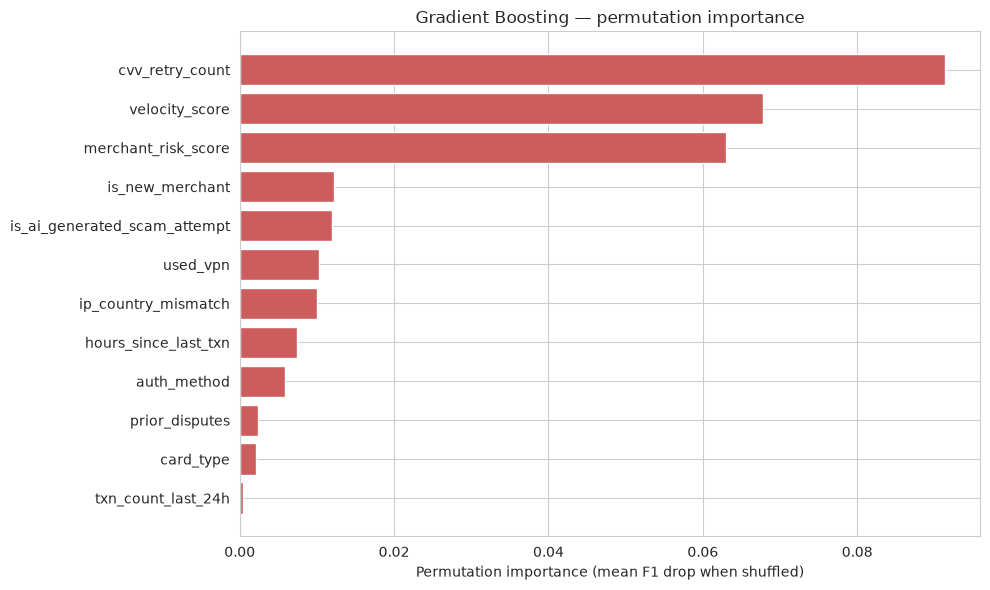

In [9]:
# --- Which clues matter to Gradient Boosting? (permutation importance) ---
# HistGradientBoostingClassifier doesn't expose feature_importances_ directly;
# use the more reliable permutation_importance instead.
from sklearn.inspection import permutation_importance  # idea: shuffle one column, see how much the score drops

# Use the already-fitted gb_pipe
result = permutation_importance(
    gb_pipe, X_test, y_test,      # measure on the honest test set
    n_repeats=5,                  # shuffle each column 5 times and average (reduces luck)
    random_state=42, n_jobs=-1, scoring="f1",
)

# permutation_importance on a Pipeline reports importance per RAW input column
# (the 10 columns in X_test), not the 17 post-preprocessing columns.
perm_df = pd.DataFrame({
    "feature":    X_test.columns,           # original column names
    "importance": result.importances_mean,  # average F1 drop when that column is scrambled
}).sort_values("importance", ascending=False)

print("Top 10 features by PERMUTATION importance:")
print(perm_df.head(10).to_string(index=False))

# Plot as a horizontal bar chart, biggest on top
fig, ax = plt.subplots(figsize=(10, 6))
top = perm_df.head(12).iloc[::-1]
ax.barh(top["feature"], top["importance"], color="indianred", edgecolor="white")
ax.set_xlabel("Permutation importance (mean F1 drop when shuffled)")
ax.set_title("Gradient Boosting — permutation importance")
plt.tight_layout()
plt.show()

## ✅ Section Summary

| Model | CV F1 (default settings + class_weight='balanced') |
|---|---|
| Random Forest (NB 05 baseline) | ~0.324 |
| Gradient Boosting (defaults) | ~0.233 |
| Gradient Boosting + early stopping | ~0.225 |

(Numbers vary slightly run-to-run. At defaults, RF typically edges out GB — the gap narrows or reverses after tuning.)

**Key insights from today:**
- **Boosting trains trees sequentially**, each fitting the residuals of the previous ensemble.
- **`learning_rate` and `max_iter` trade off** — smaller rates need more trees but generalise better.
- **Early stopping** lets the model pick `max_iter` automatically — use it as a default.
- **Permutation importance** is the more reliable feature-importance measure for boosted models.